# Praktikum 1: Preprocessing dan Visualisasi Dataset Iris

Notebook turunan dari **Praktikum 1: Iris Classification**, difokuskan hanya pada pemahaman data, pemeriksaan dan preprocessing dasar, serta visualisasi. Dataset menggunakan implementasi Iris klasik melalui `scikit-learn`; tugas ini tidak melatih atau mengevaluasi model.

**Batas pengerjaan:** berhenti setelah correlation heatmap. Training KNN, Decision Tree, Random Forest, model klasifikasi lain, accuracy, confusion matrix, dan prediksi termasuk **lanjutan untuk proses machine learning**, bukan bagian laporan ini.

## 1. Import library
Pustaka yang digunakan mencakup pandas/NumPy untuk pengolahan data, Matplotlib/Seaborn untuk visualisasi, dan `load_iris` untuk memuat dataset. Pustaka classifier dari notebook asli tidak diperlukan pada tahap ini.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

## 2. Load dataset Iris
Dataset Iris klasik dimuat dari `scikit-learn`. Data ini juga dikenal sebagai dataset Iris dari UCI yang dirujuk dalam instruksi tugas. Fitur diukur dalam sentimeter; `target` adalah kode spesies.

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
species_names = dict(enumerate(iris.target_names))
df["species"] = df["target"].map(species_names)

print("Bentuk dataset:", df.shape)
print("Nama spesies:", iris.target_names.tolist())
display(df.head())

Bentuk dataset: (150, 6)
Nama spesies: ['setosa', 'versicolor', 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 3. Data understanding
Dataset memuat 150 observasi, empat fitur pengukuran numerik, satu kolom kode target, dan satu label spesies untuk memudahkan interpretasi. Setiap spesies terdiri dari 50 observasi. Kode target 0, 1, dan 2 masing-masing dipetakan ke setosa, versicolor, dan virginica.

In [3]:
print("Informasi struktur dataset:")
df.info()
print("\nDistribusi spesies:")
display(df["species"].value_counts().rename_axis("species").to_frame("jumlah"))

Informasi struktur dataset:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB

Distribusi spesies:


,jumlah
species,
setosa,50
versicolor,50
virginica,50


## 4. Pemeriksaan missing value
Nilai kosong dihitung untuk setiap kolom. Pemeriksaan dilakukan sebelum pemodelan agar strategi imputasi dapat dipilih bila ditemukan data hilang. Pada dataset Iris ini, tidak terdapat missing value sehingga imputasi tidak diperlukan.

In [4]:
missing_summary = df.isna().sum().rename("missing").to_frame()
display(missing_summary)
print("Total missing value:", int(df.isna().sum().sum()))

,missing
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
target,0
species,0


Total missing value: 0


## 5. Pemeriksaan data duplikat
Duplikat diperiksa pada seluruh kolom, termasuk spesies. Dataset memiliki satu baris yang seluruh nilainya sama dengan observasi lain. Baris tersebut **tidak otomatis dihapus**: pada data pengukuran, observasi yang sama dapat muncul secara sah. Keputusan penghapusan sebaiknya mempertimbangkan asal dan aturan pengumpulan data; untuk eksplorasi ini seluruh 150 observasi dipertahankan.

In [5]:
duplicate_count = int(df.duplicated().sum())
print("Jumlah baris duplikat persis:", duplicate_count)
if duplicate_count:
    display(df.loc[df.duplicated(keep=False)].sort_values(list(df.columns)))

Jumlah baris duplikat persis: 1


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
101,5.8,2.7,5.1,1.9,2,virginica
142,5.8,2.7,5.1,1.9,2,virginica


## 6. Statistik deskriptif
Statistik deskriptif merangkum count, mean, standar deviasi, minimum, kuartil, dan maksimum bagi fitur numerik. Kolom target berkode angka dan tidak ditafsirkan sebagai ukuran kontinu. Statistik spesies ditampilkan terpisah sebagai jumlah kategori.

In [6]:
feature_columns = iris.feature_names
print("Statistik deskriptif fitur (cm):")
display(df[feature_columns].describe().T)
print("\nJumlah tiap spesies:")
display(df["species"].value_counts().sort_index().rename_axis("species").to_frame("jumlah"))

Statistik deskriptif fitur (cm):


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5



Jumlah tiap spesies:


,jumlah
species,
setosa,50
versicolor,50
virginica,50


## 7. Histogram fitur
Histogram menampilkan sebaran masing-masing ukuran bunga, dibedakan menurut spesies. Visualisasi ini membantu melihat bentuk distribusi, rentang, dan tumpang tindih antarkelompok. Fitur petal cenderung membedakan spesies lebih jelas daripada sepal.

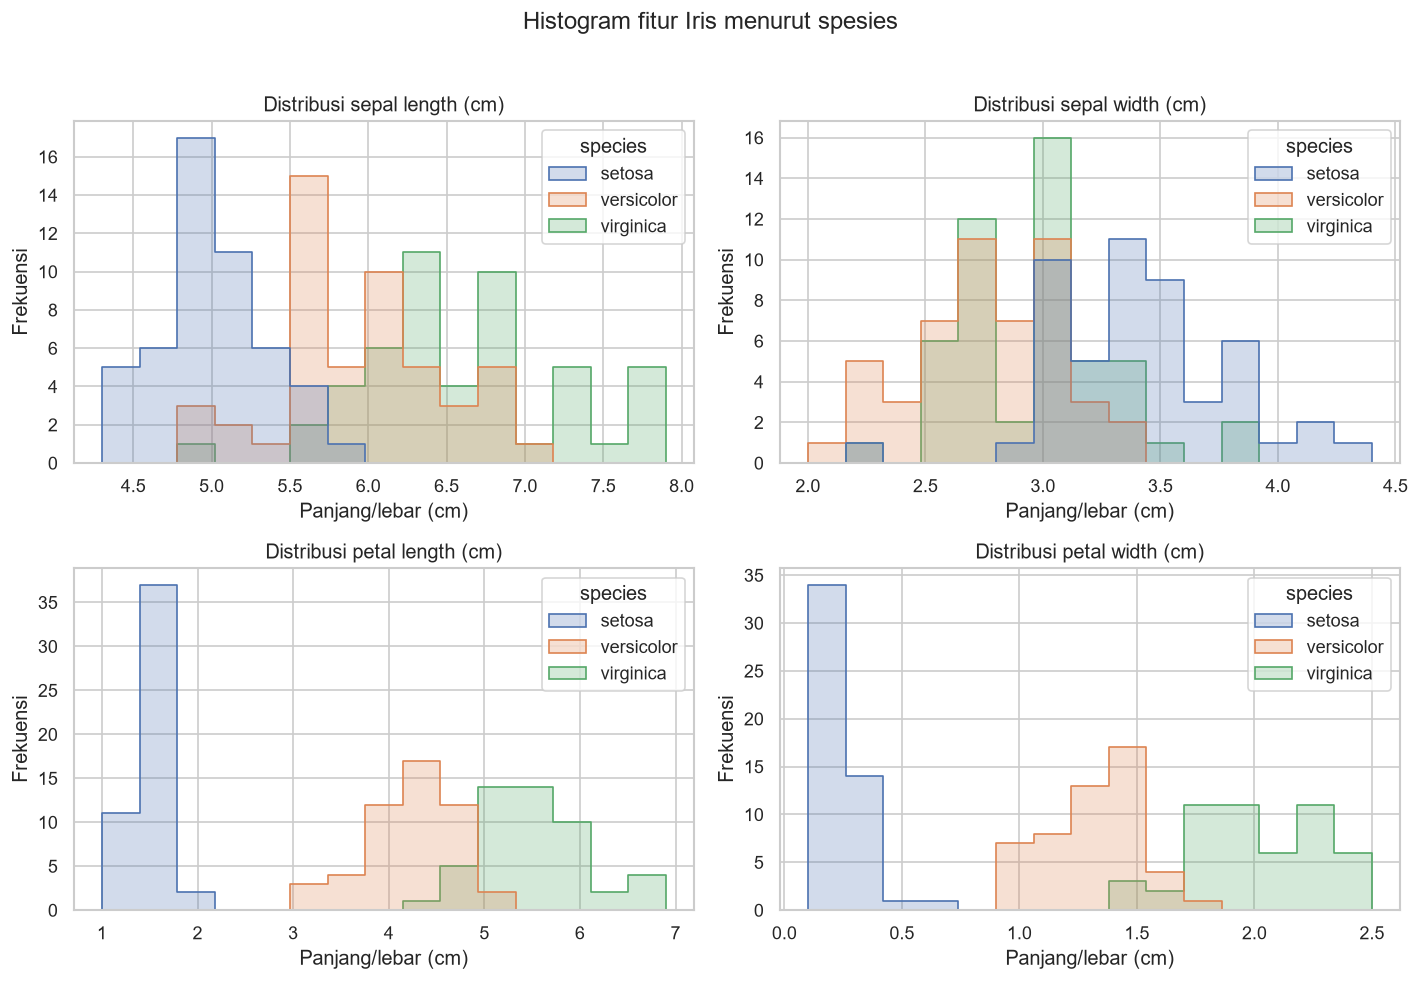

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(feature_columns, axes.flat):
    sns.histplot(data=df, x=feature, hue="species", bins=15, element="step",
                 stat="count", common_norm=False, ax=ax)
    ax.set_title(f"Distribusi {feature}")
    ax.set_xlabel("Panjang/lebar (cm)")
    ax.set_ylabel("Frekuensi")
fig.suptitle("Histogram fitur Iris menurut spesies", y=1.02)
plt.tight_layout()
plt.show()

## 8. Boxplot fitur
Boxplot membandingkan median, kuartil, rentang, dan kemungkinan nilai pencilan setiap fitur antarspesies. Kotak dan whisker digunakan sebagai ringkasan distribusi; titik di luar whisker tidak otomatis berarti kesalahan data.

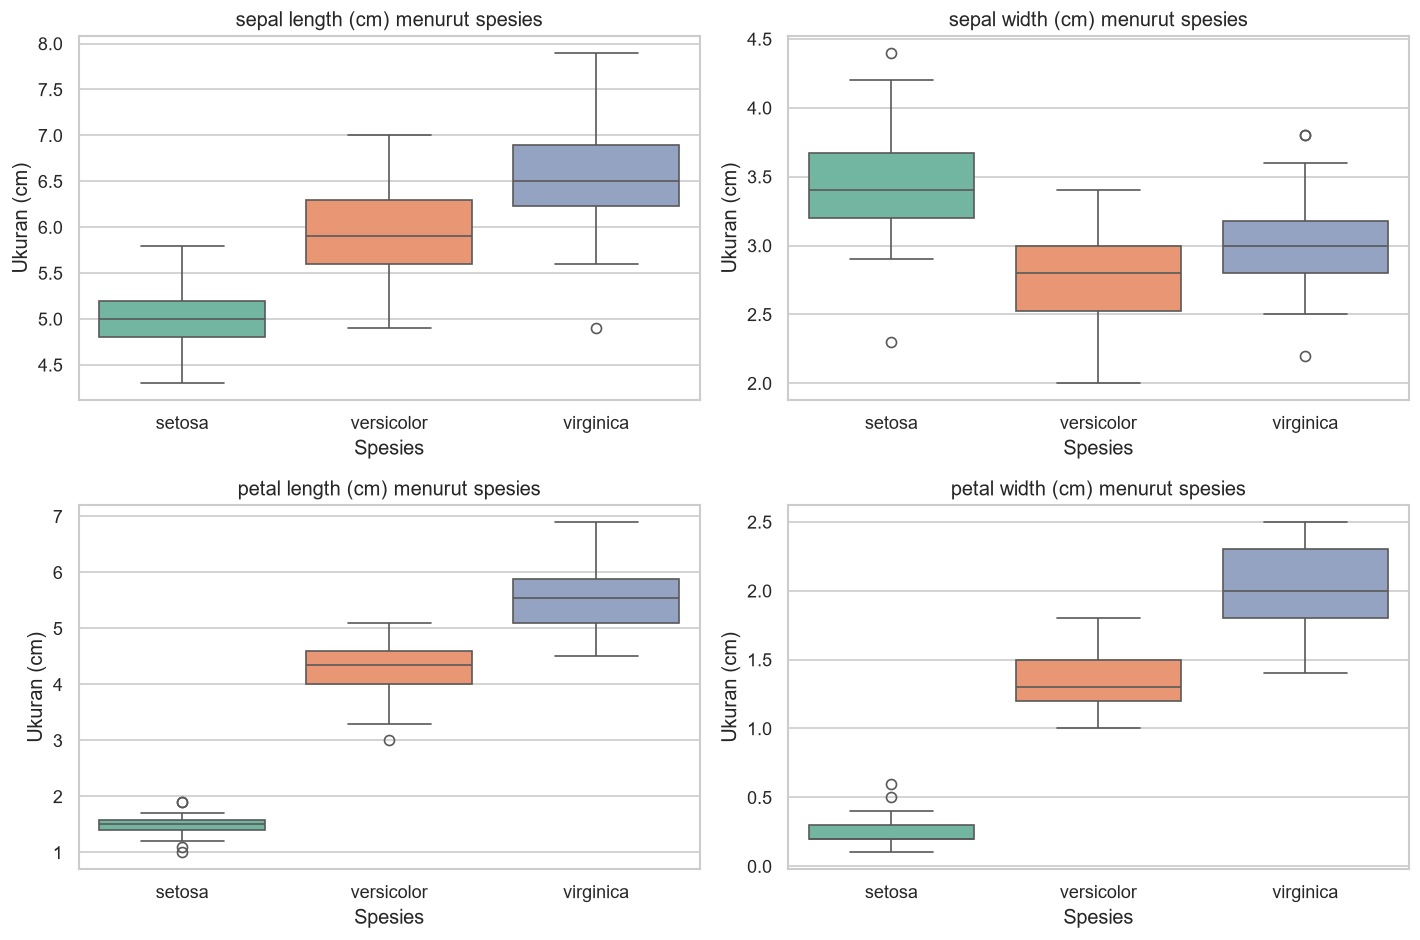

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(feature_columns, axes.flat):
    sns.boxplot(data=df, x="species", y=feature, hue="species", legend=False,
                order=iris.target_names, ax=ax, palette="Set2")
    ax.set_title(f"{feature} menurut spesies")
    ax.set_xlabel("Spesies")
    ax.set_ylabel("Ukuran (cm)")
plt.tight_layout()
plt.show()

## 9. Scatter plot
Scatter plot membandingkan panjang dan lebar petal. Warna merepresentasikan spesies. Plot membantu mengamati pola pasangan fitur dan kelompok yang terbentuk; visualisasi ini bersifat deskriptif dan tidak menunjukkan hubungan sebab-akibat.

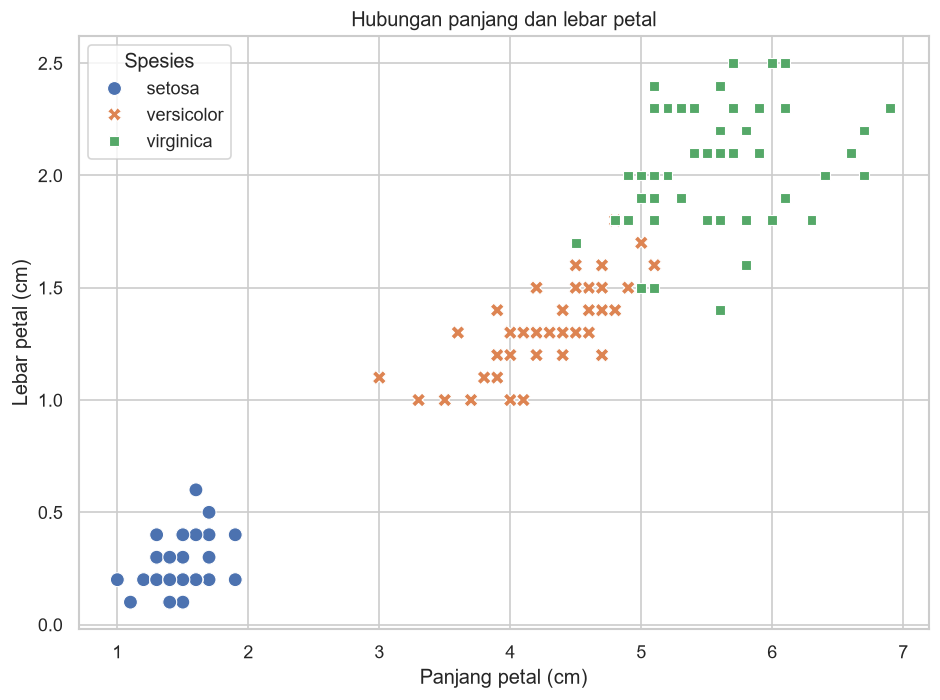

In [9]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="petal length (cm)", y="petal width (cm)",
                hue="species", style="species", s=70, palette="deep")
plt.title("Hubungan panjang dan lebar petal")
plt.xlabel("Panjang petal (cm)")
plt.ylabel("Lebar petal (cm)")
plt.legend(title="Spesies")
plt.tight_layout()
plt.show()

## 10. Pairplot
Pairplot menampilkan histogram kepadatan pada diagonal dan scatter plot untuk setiap pasangan fitur lainnya. Warna menunjukkan spesies. Plot ini memberi gambaran multivariat dan memperlihatkan bahwa fitur petal membentuk kelompok spesies yang relatif terpisah, sementara fitur sepal lebih banyak tumpang tindih.

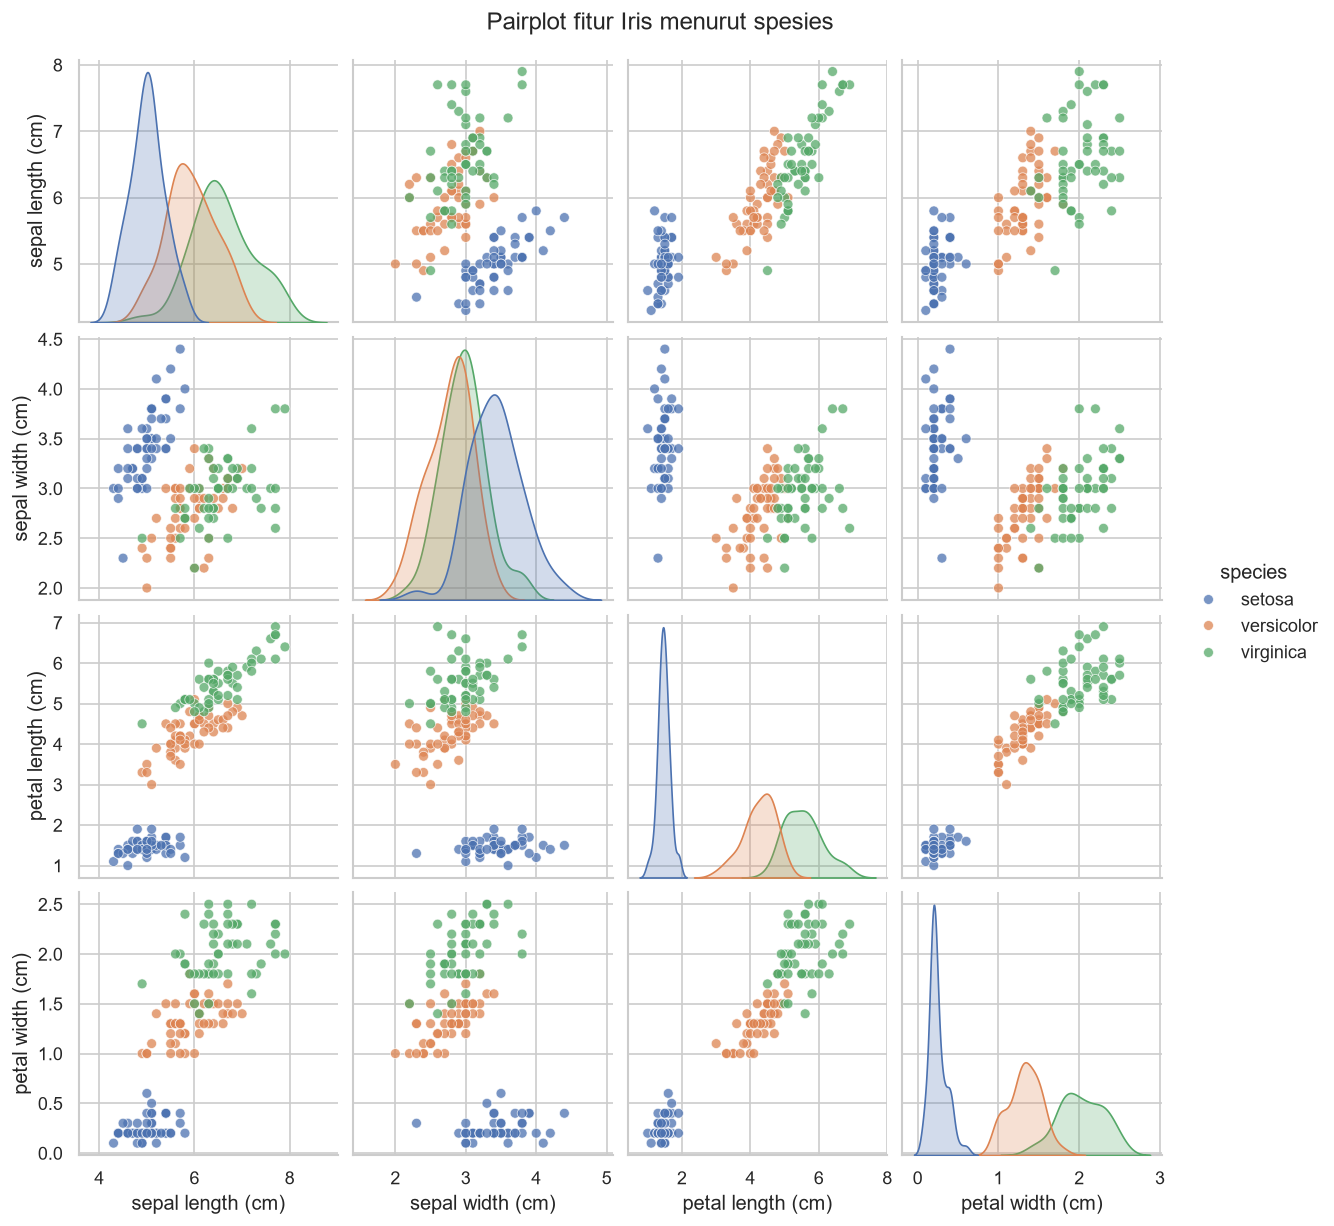

In [10]:
pair_grid = sns.pairplot(
    df, vars=feature_columns, hue="species", diag_kind="kde",
    palette="deep", plot_kws={"alpha": 0.75, "s": 35}
)
pair_grid.fig.suptitle("Pairplot fitur Iris menurut spesies", y=1.02)
plt.show()

## 11. Correlation heatmap
Heatmap menunjukkan korelasi Pearson antarempat fitur numerik. Kolom `target` tidak disertakan karena kode spesies 0?2 adalah label kategori, bukan besaran kontinu. Korelasi positif petal length dan petal width menggambarkan perubahan yang cenderung searah, bukan hubungan kausal.

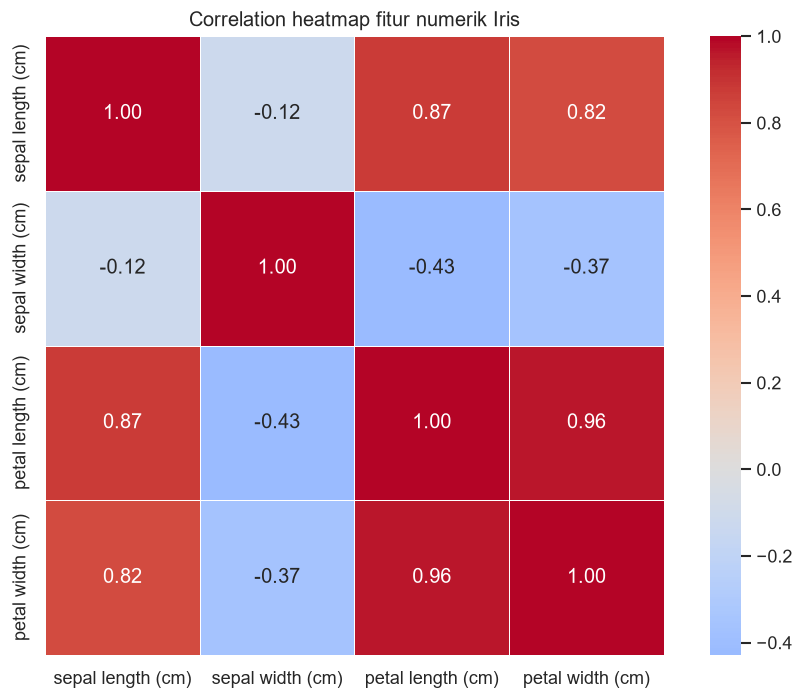

In [11]:
correlation = df[feature_columns].corr(numeric_only=True)
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5)
plt.title("Correlation heatmap fitur numerik Iris")
plt.tight_layout()
plt.show()

## Batas tugas dan tahap lanjutan
Laporan ini membahas preprocessing dasar dan visualisasi, lalu berhenti di heatmap. Bagian pada notebook asli setelah tahap visualisasi?pemisahan fitur-target untuk model, train-test split, pelatihan KNN/Decision Tree/Random Forest atau classifier lain, accuracy, confusion matrix, classification report, dan prediksi?ditandai sebagai **lanjutan untuk proses machine learning** dan tidak dibahas dalam laporan preprocessing ini.